# Predicción de impago de tarjetas de crédito (Taiwán, 2005)

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import binomtest, chi2_contingency

In [2]:
DATA_PATH = "UCI_Credit_Card.csv"
FEATURES_PATH = "credit_features.csv"
TARGET = "default"
PAY_STATUS_COLUMNS = [f"PAY_{month}" for month in range(1, 7)]
BILL_COLUMNS = [f"BILL_AMT{month}" for month in range(1, 7)]
PAYMENT_COLUMNS = [f"PAY_AMT{month}" for month in range(1, 7)]
STATUS_COLUMNS = [f"STATUS_{month}" for month in range(1, 7)]
DELAY_COLUMNS = [f"DELAY_{month}" for month in range(1, 7)]
UTILIZATION_CAP = 2
AGE_OF_LOWEST_RISK = 33

## 1. Introducción

Clientes de tarjetas de crédito en Taiwán, con datos de abril a septiembre de 2005. El objetivo es predecir si un cliente impaga el mes siguiente (`default`, 1 = impago).

Este notebook cubre la carga, la limpieza, el análisis exploratorio y la ingeniería de variables, y responde a la primera pregunta guía: **¿cómo varía el impago según las variables demográficas?** El modelado está en `02_Modelado_CC` y la evaluación en `03_Evaluacion_CC`.

## 2. Carga de datos

Renombramos `PAY_0` a `PAY_1` para que los índices de las tres series temporales coincidan (1 = septiembre, 6 = abril) y la variable objetivo a `default` para quitar los puntos del nombre. El DataFrame original `credit_raw` no se modifica.

In [3]:
credit_raw = pd.read_csv(DATA_PATH)
credit = credit_raw.rename(columns={"default.payment.next.month": TARGET, "PAY_0": "PAY_1"})
credit.head()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_1,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default
0,1,20000.0,2,2,1,24,2,2,-1,-1,...,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,2,120000.0,2,2,2,26,-1,2,0,0,...,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,3,90000.0,2,2,2,34,0,0,0,0,...,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,4,50000.0,2,2,1,37,0,0,0,0,...,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,5,50000.0,1,2,1,57,-1,0,-1,0,...,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0


## 3. Limpieza

Aplicamos la codificación corregida del autor sobre una copia, `credit_clean`:

| Variable | Valor | Etiqueta |
|---|---|---|
| `EDUCATION` | 1 / 2 / 3 | posgrado / universidad / bachillerato |
| | 0, 4, 5, 6 | otros |
| `MARRIAGE` | 1 / 2 / 3 / 0 | casado / soltero / divorciado / otros |
| `PAY_*` | -2 / -1 / 0 | sin consumo / pagado en su totalidad / revolving |
| | 1 … 9 | meses de retraso |

Se conservan todas las filas. Los importes negativos y extremos se tratarán en la ingeniería de variables.

In [4]:
sex_labels = {1: "hombre", 2: "mujer"}
education_labels = {
    1: "posgrado", 2: "universidad", 3: "bachillerato",
    0: "otros", 4: "otros", 5: "otros", 6: "otros",
}
marriage_labels = {1: "casado", 2: "soltero", 3: "divorciado", 0: "otros"}

credit_clean = credit.copy()
credit_clean["SEX"] = credit["SEX"].map(sex_labels)
credit_clean["EDUCATION"] = credit["EDUCATION"].map(education_labels)
credit_clean["MARRIAGE"] = credit["MARRIAGE"].map(marriage_labels)

Cada `PAY_*` mezcla el tipo de uso del crédito (-2, -1, 0) y los meses de retraso (1 a 9). La separamos en dos variables más sencillas que una categórica de 11 niveles:

- `STATUS_*`: tipo de uso (sin consumo, pagado en su totalidad, revolving o retraso).
- `DELAY_*`: meses de retraso, 0 si el código es ≤ 0.

In [5]:
status_labels = {-2: "sin_consumo", -1: "pago_total", 0: "revolving", 1: "retraso"}

for month in range(1, 7):
    pay_column = f"PAY_{month}"
    credit_clean[f"STATUS_{month}"] = credit[pay_column].clip(upper=1).map(status_labels)
    credit_clean[f"DELAY_{month}"] = credit[pay_column].clip(lower=0)

credit_clean = credit_clean.drop(columns=PAY_STATUS_COLUMNS)

## 4. Análisis exploratorio

### 4.1 Variable objetivo

In [6]:
credit_clean[TARGET].value_counts(normalize=True).round(3)

default
0    0.779
1    0.221
Name: proportion, dtype: float64

El 22,1 % de los clientes impaga. Un modelo que prediga siempre "no impago" tendría una accuracy del 77,9 % sin detectar ningún impago. Por eso las métricas principales serán PR-AUC, ROC-AUC y el recall y la precisión de la clase 1, y las particiones serán estratificadas.

### 4.2 Impago por grupos

Respondemos a la primera pregunta guía: ¿cómo varía el impago según las variables demográficas? Para cada grupo calculamos la tasa de impago con un intervalo de confianza de Wilson al 95 %. La edad y el límite se agrupan en tramos solo para este análisis, en una copia aparte (`credit_eda`).

In [7]:
def default_rate_with_ci(data, column):
    rows = []
    for group, group_target in data.groupby(column, observed=True)[TARGET]:
        test_result = binomtest(int(group_target.sum()), len(group_target))
        interval = test_result.proportion_ci(method="wilson")
        rows.append({
            column: group,
            "clientes": len(group_target),
            "tasa_impago": group_target.mean(),
            "ic_inferior": interval.low,
            "ic_superior": interval.high,
        })
    return pd.DataFrame(rows).set_index(column).round(3)

In [8]:
overall_default_rate = credit_clean[TARGET].mean()


def plot_default_rate(rate_table, title, xlabel):
    lower_error = rate_table["tasa_impago"] - rate_table["ic_inferior"]
    upper_error = rate_table["ic_superior"] - rate_table["tasa_impago"]
    ax = rate_table["tasa_impago"].plot(
        kind="bar",
        yerr=np.array([lower_error, upper_error]),
        capsize=4,
        rot=0,
        label="Tasa del grupo (IC 95 %)",
    )
    ax.axhline(overall_default_rate, color="grey", linestyle="--", label="Tasa global")
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Tasa de impago")
    ax.legend()
    plt.show()

In [9]:
age_bins = [20, 25, 30, 35, 40, 45, 50, 60, 80]
limit_bins = [0, 50_000, 100_000, 200_000, 300_000, 500_000, 1_000_000]
limit_labels = ["≤50k", "50k–100k", "100k–200k", "200k–300k", "300k–500k", ">500k"]

credit_eda = credit_clean.assign(
    AGE_BAND=pd.cut(credit_clean["AGE"], bins=age_bins),
    LIMIT_BAND=pd.cut(credit_clean["LIMIT_BAL"], bins=limit_bins, labels=limit_labels),
)

### 4.3 Educación

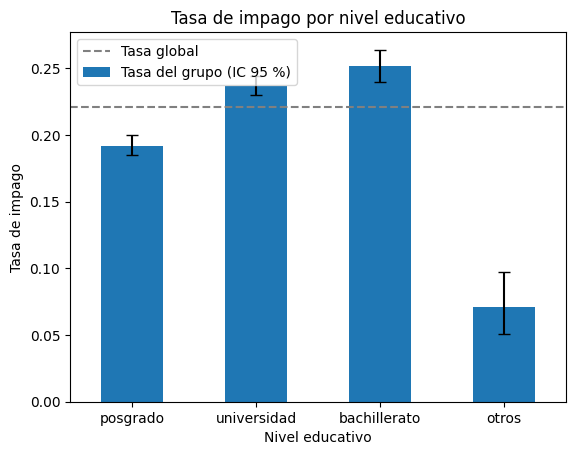

In [10]:
education_order = ["posgrado", "universidad", "bachillerato", "otros"]
education_default = default_rate_with_ci(credit_eda, "EDUCATION").loc[education_order]
plot_default_rate(education_default, "Tasa de impago por nivel educativo", "Nivel educativo")

Cuanto menor es el nivel educativo, mayor es el impago: 19,2 % con posgrado, 23,7 % con universidad y 25,2 % con bachillerato. El grupo "otros" (7,1 %) no debe leerse como un nivel educativo: agrupa varios códigos residuales y su tasa anómala probablemente responde a cómo se registraron esos clientes.

### 4.4 Edad

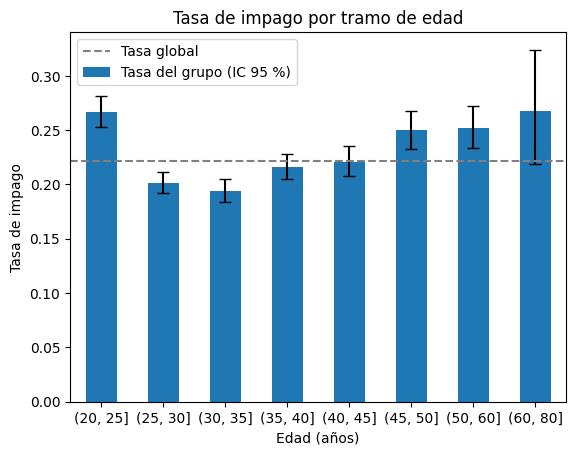

In [11]:
age_default = default_rate_with_ci(credit_eda, "AGE_BAND")
plot_default_rate(age_default, "Tasa de impago por tramo de edad", "Edad (años)")

La relación tiene forma de U. El impago es máximo entre los más jóvenes (26,7 % de 21 a 25 años), mínimo entre los 26 y los 35 (19–20 %) y vuelve a subir a partir de los 45 (25 %). Por eso una regresión logística que use la edad como variable lineal no capturará bien esta relación; habrá que usar tramos o un término cuadrático.

### 4.5 Límite de crédito

No es una variable demográfica, pero el límite lo asigna el banco a partir de su propia valoración del cliente y puede explicar parte de las diferencias anteriores.

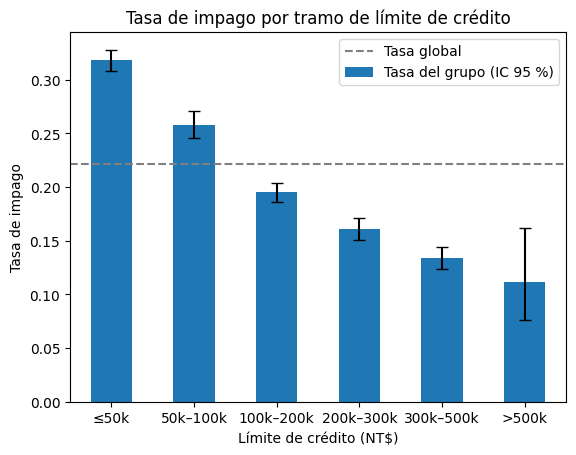

In [12]:
limit_default = default_rate_with_ci(credit_eda, "LIMIT_BAND")
plot_default_rate(
    limit_default, "Tasa de impago por tramo de límite de crédito", "Límite de crédito (NT$)"
)

Es el gradiente más claro: el impago baja de forma continua del 31,8 % con límites de hasta 50.000 NT$ al 11,2 % con más de 500.000. Hay que leerlo como correlación, no como causa. El banco asigna límites altos a quienes ya considera solventes, así que el límite incorpora la valoración previa del riesgo; subir el límite a un cliente no reduciría su riesgo.

### 4.6 Sexo y estado civil

Son las dos asociaciones más débiles, así que mostramos solo sus tasas con los intervalos de confianza.

In [13]:
pd.concat({
    "SEX": default_rate_with_ci(credit_eda, "SEX"),
    "MARRIAGE": default_rate_with_ci(credit_eda, "MARRIAGE"),
})

clientes  tasa_impago  ic_inferior  ic_superior
SEX      hombre         11888        0.242        0.234        0.249
         mujer          18112        0.208        0.202        0.214
MARRIAGE casado         13659        0.235        0.228        0.242
         divorciado       323        0.260        0.215        0.311
         otros             54        0.093        0.040        0.199
         soltero        15964        0.209        0.203        0.216

Los hombres impagan 3,4 puntos más que las mujeres (24,2 % frente a 20,8 %), con intervalos que no se solapan. Los casados impagan más que los solteros (23,5 % frente a 20,9 %). Los divorciados tienen la tasa más alta (26,0 %), pero con un intervalo ancho (21,5–31,1 %), y "otros" (54 clientes) no es fiable.

### 4.7 Contraste de independencia

Con 30.000 clientes, hasta diferencias pequeñas salen significativas en la prueba chi-cuadrado, así que la V de Cramér (de 0 a 1) es la que mide si la asociación es relevante.

In [14]:
test_rows = []
for column in ["SEX", "EDUCATION", "MARRIAGE", "AGE_BAND", "LIMIT_BAND"]:
    contingency = pd.crosstab(credit_eda[column], credit_eda[TARGET])
    chi2, p_value, degrees_of_freedom, _ = chi2_contingency(contingency)
    cramers_v = np.sqrt(chi2 / contingency.to_numpy().sum())
    test_rows.append({
        "variable": column,
        "chi2": chi2,
        "gl": degrees_of_freedom,
        "p_valor": p_value,
        "v_cramer": cramers_v,
    })

test_results = pd.DataFrame(test_rows).set_index("variable")
test_results.sort_values("v_cramer", ascending=False).round({"chi2": 1, "v_cramer": 3})

,chi2,gl,p_valor,v_cramer
variable,,,,
LIMIT_BAND,802.9,5,2.727457e-171,0.164
EDUCATION,160.4,3,1.495065e-34,0.073
AGE_BAND,114.2,7,1.223505e-21,0.062
SEX,47.7,1,4.944679e-12,0.040
MARRIAGE,35.7,3,8.825862e-08,0.034


Todas las diferencias son significativas (p < 0,001), pero su tamaño es modesto. El límite de crédito tiene la asociación más fuerte (V = 0,16), seguido de lejos por educación (0,07) y edad (0,06). Sexo (0,04) y estado civil (0,03) apenas se asocian con el impago.

### 4.8 Conclusiones sobre la primera pregunta guía

- El impago varía de forma significativa en todos los grupos, pero **las diferencias demográficas son pequeñas** (V de Cramér de 0,03 a 0,07): bachillerato frente a posgrado (25,2 % frente a 19,2 %), menores de 25 y mayores de 60 frente a 31–35 años (≈ 27 % frente a 19,4 %), y hombres frente a mujeres (24,2 % frente a 20,8 %).
- **El límite de crédito marca la mayor diferencia** (31,8 % frente a 11,2 %; V = 0,16), pero el banco lo asigna según su propia valoración del riesgo, así que es una correlación, no una causa.
- `SEX`, `AGE` y `MARRIAGE` son atributos sensibles que en muchas jurisdicciones no pueden usarse en decisiones de crédito.

## 5. Ingeniería de variables

Resumimos los seis meses de historial de cada cliente en variables con sentido de negocio. Se calculan fila a fila con datos de abril a septiembre, la información disponible al predecir el impago de octubre, así que no hay fuga de información. Trabajamos sobre una copia nueva, `credit_features`.

- **Utilización** (`UTILIZATION_*`): factura / límite en septiembre, media y máximo, con un tope de 2 (`UTILIZATION_CAP`). Los saldos a favor (negativos) se conservan.
- **Ratio de pago** (`PAYMENT_RATIO_*`): pago de un mes / factura del mes anterior, con un tope de 1, y 1 si no había nada que pagar.
- **Retrasos y tipo de uso**: meses con retraso, peor retraso y meses en cada tipo de uso.
- **Edad** (`AGE_SQUARED_DEVIATION`): distancia al cuadrado a 33 años, para que la regresión logística capte la forma en U.
- **Deuda, importes y actividad**: tendencia de la deuda (septiembre − abril, sobre el límite), logaritmos del límite y de los pagos, e `INACTIVE` (sin facturas ni pagos en seis meses).

In [15]:
credit_features = credit_clean.copy()
utilization = credit_clean[BILL_COLUMNS].div(credit_clean["LIMIT_BAL"], axis=0)
utilization = utilization.clip(upper=UTILIZATION_CAP)

credit_features["UTILIZATION_LAST"] = utilization["BILL_AMT1"]
credit_features["UTILIZATION_MEAN"] = utilization.mean(axis=1)
credit_features["UTILIZATION_MAX"] = utilization.max(axis=1)

payment_ratios = pd.DataFrame(index=credit_clean.index)
for month in range(1, 6):
    payment = credit_clean[f"PAY_AMT{month}"]
    previous_bill = credit_clean[f"BILL_AMT{month + 1}"]
    ratio = (payment / previous_bill).where(previous_bill > 0, 1)
    payment_ratios[month] = ratio.clip(upper=1)

credit_features["PAYMENT_RATIO_LAST"] = payment_ratios[1]
credit_features["PAYMENT_RATIO_MEAN"] = payment_ratios.mean(axis=1)

In [16]:
credit_features["MONTHS_DELAYED"] = (credit_clean[DELAY_COLUMNS] > 0).sum(axis=1)
credit_features["WORST_DELAY"] = credit_clean[DELAY_COLUMNS].max(axis=1)

status_feature_names = {
    "revolving": "MONTHS_REVOLVING",
    "pago_total": "MONTHS_PAID_FULL",
    "sin_consumo": "MONTHS_NO_USE",
}
for status, feature_name in status_feature_names.items():
    credit_features[feature_name] = (credit_clean[STATUS_COLUMNS] == status).sum(axis=1)

age_deviation = credit_clean["AGE"] - AGE_OF_LOWEST_RISK
credit_features["AGE_SQUARED_DEVIATION"] = age_deviation ** 2

In [17]:
bill_change = credit_clean["BILL_AMT1"] - credit_clean["BILL_AMT6"]
debt_trend = bill_change / credit_clean["LIMIT_BAL"]
credit_features["DEBT_TREND"] = debt_trend.clip(-UTILIZATION_CAP, UTILIZATION_CAP)

credit_features["LOG_LIMIT"] = np.log(credit_clean["LIMIT_BAL"])
credit_features["LOG_PAYMENT_LAST"] = np.log1p(credit_clean["PAY_AMT1"])
credit_features["LOG_PAYMENT_MEAN"] = np.log1p(credit_clean[PAYMENT_COLUMNS].mean(axis=1))

no_activity = (credit_clean[BILL_COLUMNS + PAYMENT_COLUMNS] == 0).all(axis=1)
credit_features["INACTIVE"] = no_activity.astype(int)

### 5.1 Redundancia entre las variables nuevas

Si dos variables dicen casi lo mismo, conservar las dos hace inestables los coeficientes de la regresión logística. Buscamos pares con una correlación absoluta superior a 0,85.

In [18]:
candidate_numeric_features = [
    "AGE", "AGE_SQUARED_DEVIATION", "LOG_LIMIT",
    "DELAY_1", "MONTHS_DELAYED", "WORST_DELAY", "MONTHS_PAID_FULL", "MONTHS_NO_USE",
    "UTILIZATION_LAST", "UTILIZATION_MEAN", "UTILIZATION_MAX",
    "PAYMENT_RATIO_LAST", "PAYMENT_RATIO_MEAN", "DEBT_TREND",
    "LOG_PAYMENT_LAST", "LOG_PAYMENT_MEAN", "INACTIVE",
]
correlations = credit_features[candidate_numeric_features].corr().abs()
upper_triangle = np.triu(np.ones(correlations.shape, dtype=bool), k=1)
correlated_pairs = correlations.where(upper_triangle).stack()
correlated_pairs[correlated_pairs > 0.85].sort_values(ascending=False).round(2)

UTILIZATION_LAST    UTILIZATION_MAX       0.94
UTILIZATION_MEAN    UTILIZATION_MAX       0.93
UTILIZATION_LAST    UTILIZATION_MEAN      0.91
PAYMENT_RATIO_LAST  PAYMENT_RATIO_MEAN    0.88
dtype: float64

Hay dos familias redundantes: las tres variantes de la utilización (correlaciones de 0,91 a 0,94) y las dos del ratio de pago (0,88). De cada una conservamos la media, que resume los seis meses y es menos sensible a un mes atípico.

La correlación entre pares no detecta una variable que se explica por la combinación de varias. Para eso calculamos el factor de inflación de la varianza (VIF) de las variables que quedan. Un VIF superior a 5 indica redundancia.

In [19]:
correlated_features = ["UTILIZATION_LAST", "UTILIZATION_MAX", "PAYMENT_RATIO_LAST"]
remaining_features = [
    feature for feature in candidate_numeric_features if feature not in correlated_features
]
remaining_correlations = credit_features[remaining_features].corr().to_numpy()
variance_inflation = pd.Series(
    np.diag(np.linalg.inv(remaining_correlations)), index=remaining_features, name="VIF"
)
variance_inflation.sort_values(ascending=False).head(5).round(2)

PAYMENT_RATIO_MEAN    15.66
MONTHS_PAID_FULL       8.63
MONTHS_NO_USE          8.08
MONTHS_DELAYED         3.69
WORST_DELAY            3.65
Name: VIF, dtype: float64

`PAYMENT_RATIO_MEAN` (15,7), `MONTHS_PAID_FULL` (8,6) y `MONTHS_NO_USE` (8,1) superan el umbral: quien paga el total o no consume tiene por construcción un ratio de pago de 1. Quitamos `MONTHS_NO_USE` y todos los VIF quedan por debajo de 3,7. Conservamos así el ratio de pago, que tiene una lectura de negocio directa.

### 5.2 Selección y exportación

Las variables resumen sustituyen a las 18 columnas mensuales en bruto y a `STATUS_2`–`STATUS_6`. Quitamos también `MONTHS_REVOLVING`, redundante (con los otros tres recuentos de tipo de uso suma siempre 6), y `MONTHS_NO_USE`, por su VIF. El modelo parte de 17 variables:

| Familia | Variables |
|---|---|
| Demográficas | `SEX`, `EDUCATION`, `MARRIAGE`, `AGE`, `AGE_SQUARED_DEVIATION` |
| Crédito | `LOG_LIMIT` |
| Estado actual | `STATUS_1`, `DELAY_1` |
| Historial de retraso | `MONTHS_DELAYED`, `WORST_DELAY` |
| Tipo de uso | `MONTHS_PAID_FULL` |
| Uso y pago | `UTILIZATION_MEAN`, `PAYMENT_RATIO_MEAN`, `DEBT_TREND`, `LOG_PAYMENT_LAST`, `LOG_PAYMENT_MEAN` |
| Actividad | `INACTIVE` |

Las guardamos con la variable objetivo en `credit_features.csv`, del que parte `02_Modelado_CC`.

In [20]:
numeric_features = [
    feature for feature in remaining_features if feature != "MONTHS_NO_USE"
]
categorical_features = ["SEX", "EDUCATION", "MARRIAGE", "STATUS_1"]
model_features = categorical_features + numeric_features

pd.Series({"categóricas": len(categorical_features), "numéricas": len(numeric_features)})

categóricas     4
numéricas      13
dtype: int64

In [21]:
credit_features[model_features + [TARGET]].to_csv(FEATURES_PATH, index=False)
credit_features[model_features + [TARGET]].shape

(30000, 18)